# N109: rich H1 and rich-context H2 MPC

Status: **complete**. Active arm: **preparation/checks**.

Two independent runs use the same 91,968 reserved images in order. Each restores
the ORIGINAL pre-96k parent; all 42 offline clips / 4,032 images remain excluded.

| Arm | Transition predictor | Planning horizon |
| --- | --- | ---: |
| Rich H1 | Rich offline fit, then learns actual feedback | 1 |
| Rich H2 MPC · fixed context | Identical fit/adaptation, plans two actions, applies first | 2 |

Both use the existing 22 state/image/action inputs PLUS all 66 original Neither
features (88 coordinates). No clip position/boundary, clock, task labels,
development feedback, gradients, optimizer summaries or recent-eight similarities
enter control. Added features include current-model embeddings/projections,
cluster distances/reconstruction and extra health/history. Offline features are
reconstructed by exact replay of N106's same split-specific trajectories; original
measured action responses are reused. No online responses enter that fit.

During imagined steps, update the three predicted metrics, their histories and
actions, including all corresponding changes/means in the rich bundle. Hold other
health values, image/embedding/cluster context fixed at the measured current value.
Recompute their history differences consistently. No future images are supplied.
Both arms measure the full context again after each real arrival.

New nominal LR = 1/4 of N107 nominal, matching N108. Actions are 0, 1/16, 1/4
in ORIGINAL nominal units. Offline coefficients/design and priors use original
physical LR units; runtime rate/action history are converted consistently.

Actions: {skip,1/4 nominal,1 nominal}. All use the same5% nonzero exploration,
paired action/view seeds, numerical rollback and64-arrival cooldown. Both adaptive
models warm-start with the actual offline TRAINING sufficient statistics and
coefficients. Each successful chosen positive update supplies one measured
RankMe/reconstruction/variance change vector. Discount past evidence with a256
successful-update half-life. Scalers/target scales, ridge penalties, objective
and all other settings stay fixed. Skip/failed/untried/imagined actions do not
train a model. The immutable shadow never adapts and does not choose actions.

H1 minimizes next predicted original J. H2 minimizes summed J over two predicted
states, applies only the first action and replans after real feedback. Future raw
image statistics are held at current values; no future images, measured health,
task scores or controller updates are fed into imagined states. The original
fixed-reference J uses .25 rank and .25 variance deficit penalties.

An immutable offline shadow also forecasts each adaptive arm's ACTUAL states and
chosen actions. Paired shadow errors isolate prediction adaptation from different
plant trajectories. All forecasts are logged before feedback. One-step errors
below exclude trivial identity skips; only chosen actions have measured outcomes.
Two-step error selects the already-logged forecast for the subsequently executed
action pair, without giving future actions to the earlier controller. Include
nontrivial windows and clip boundaries; exclude numerical failures.

Task labels appear only in fixed evaluation readouts, never in predictor inputs,
updates or action decisions. This is prequential adaptation, not offline refitting
on this stream. The source96k history was inspected in older project experiments.
All arms compute two-step forecasts for common diagnostics; only H2 controls with
them, so inference timings include that diagnostic work.

| Arm | Saved images | Plant updates | Predictor updates | Available late accuracy (%) | Recorded time (min) |
| --- | ---: | ---: | ---: | ---: | ---: |
| Rich H1 | 91,968 | 9,465 | 9,465 | 59.551 | 53.40 |
| Rich H2 MPC · fixed context | 91,968 | 10,113 | 10,113 | 59.852 | 54.34 |

Common coverage across both arms: **91,968**. Available table means use each arm's saved coverage; primary comparisons use common scheduled30k--91,968 checkpoints.

## Positive-update one-step forecast RMSE

| Arm | Output | Active model | Frozen shadow, same states/actions | Persistence | Positive updates |
| --- | --- | ---: | ---: | ---: | ---: |
| Rich H1 | RankMe | 0.00542185 | 0.00871001 | 0.00986529 | 9,465 |
| Rich H1 | Reconstruction loss | 0.000485097 | 0.00152113 | 0.000738691 | 9,465 |
| Rich H1 | Variance | 1.73351e-05 | 2.48952e-05 | 3.0629e-05 | 9,465 |
| Rich H2 MPC · fixed context | RankMe | 0.0048149 | 0.00762243 | 0.00849162 | 10,113 |
| Rich H2 MPC · fixed context | Reconstruction loss | 0.000404635 | 0.00165141 | 0.00060874 | 10,113 |
| Rich H2 MPC · fixed context | Variance | 1.61462e-05 | 2.3921e-05 | 2.813e-05 | 10,113 |

RMSE is in native metric units. Different policies visit different states; the frozen-shadow comparison is paired within each plant trajectory. Per-action and two-step numbers/counts are saved in comparison.json.


## Balanced audit linear accuracy (%)

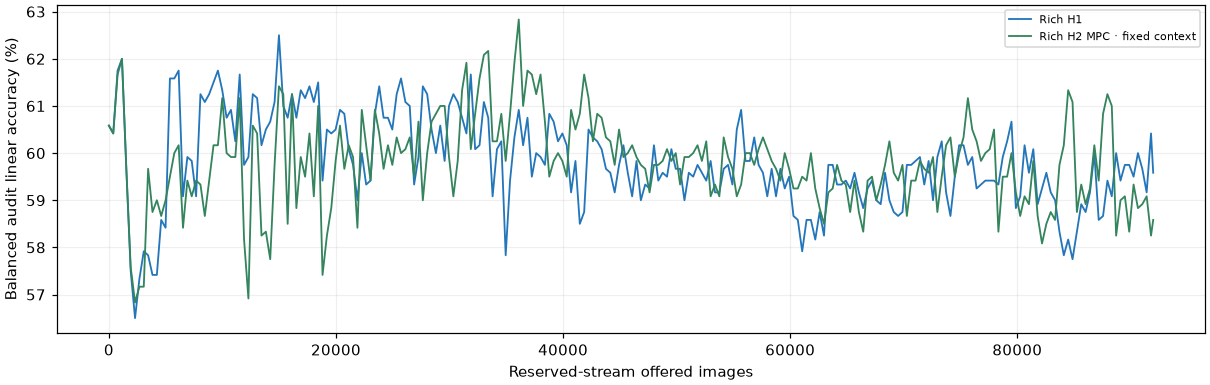



## RankMe

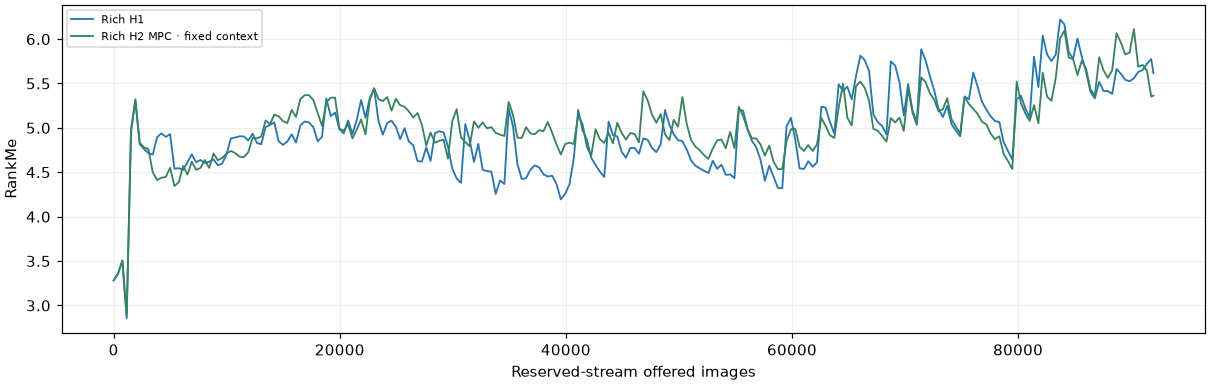



## Fixed-bank reconstruction loss

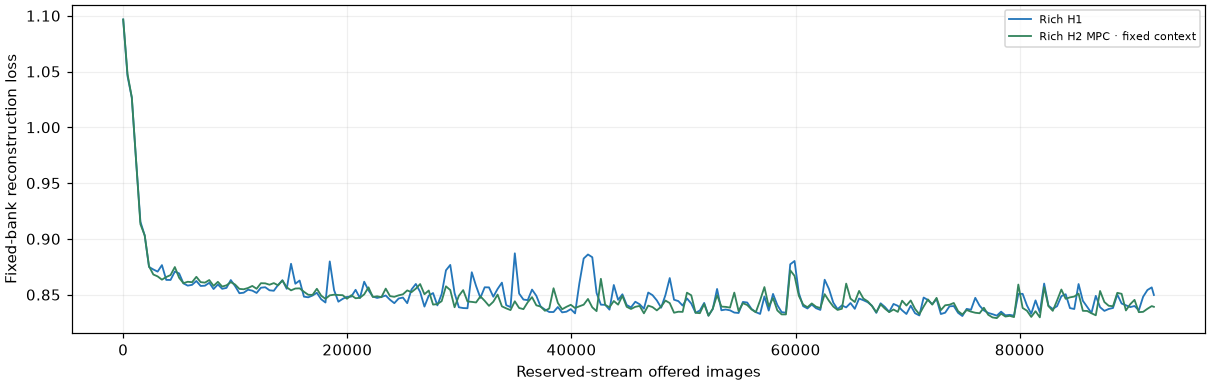



## Variance

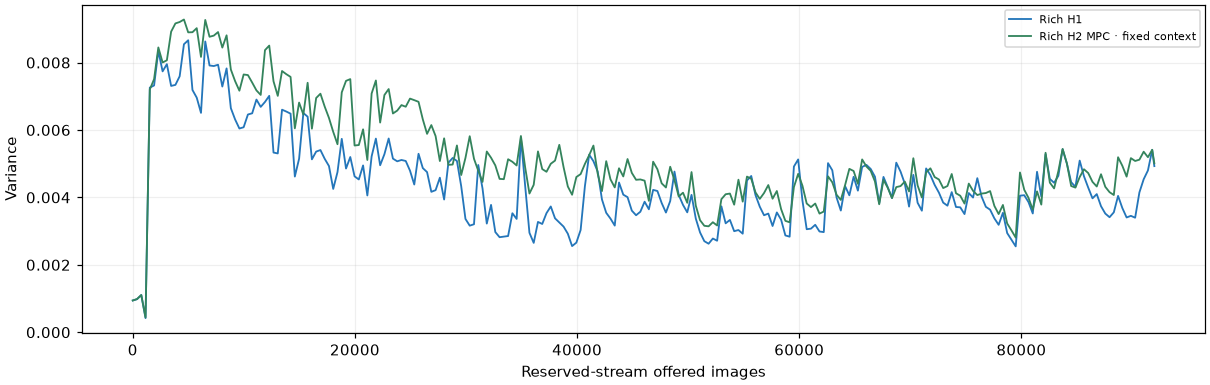



## Original fixed-bank J

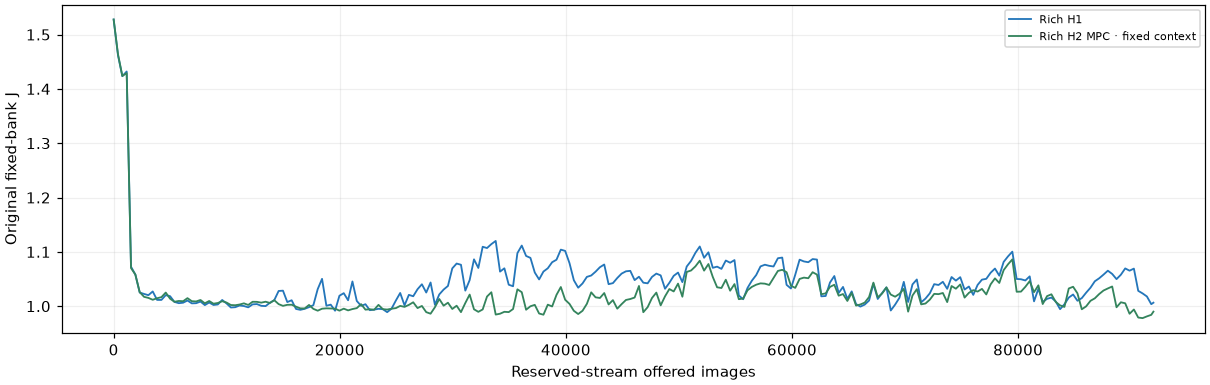



## Covariance

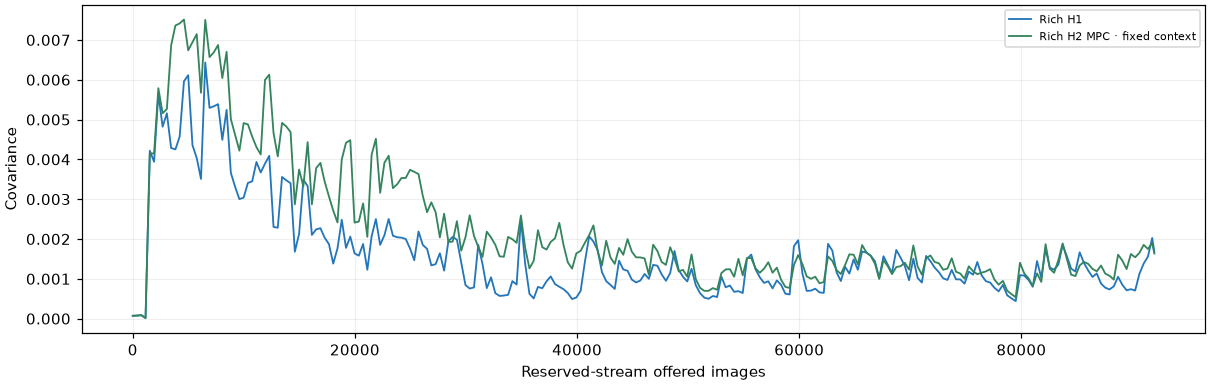



## Actual plant outputs and one-step forecasts

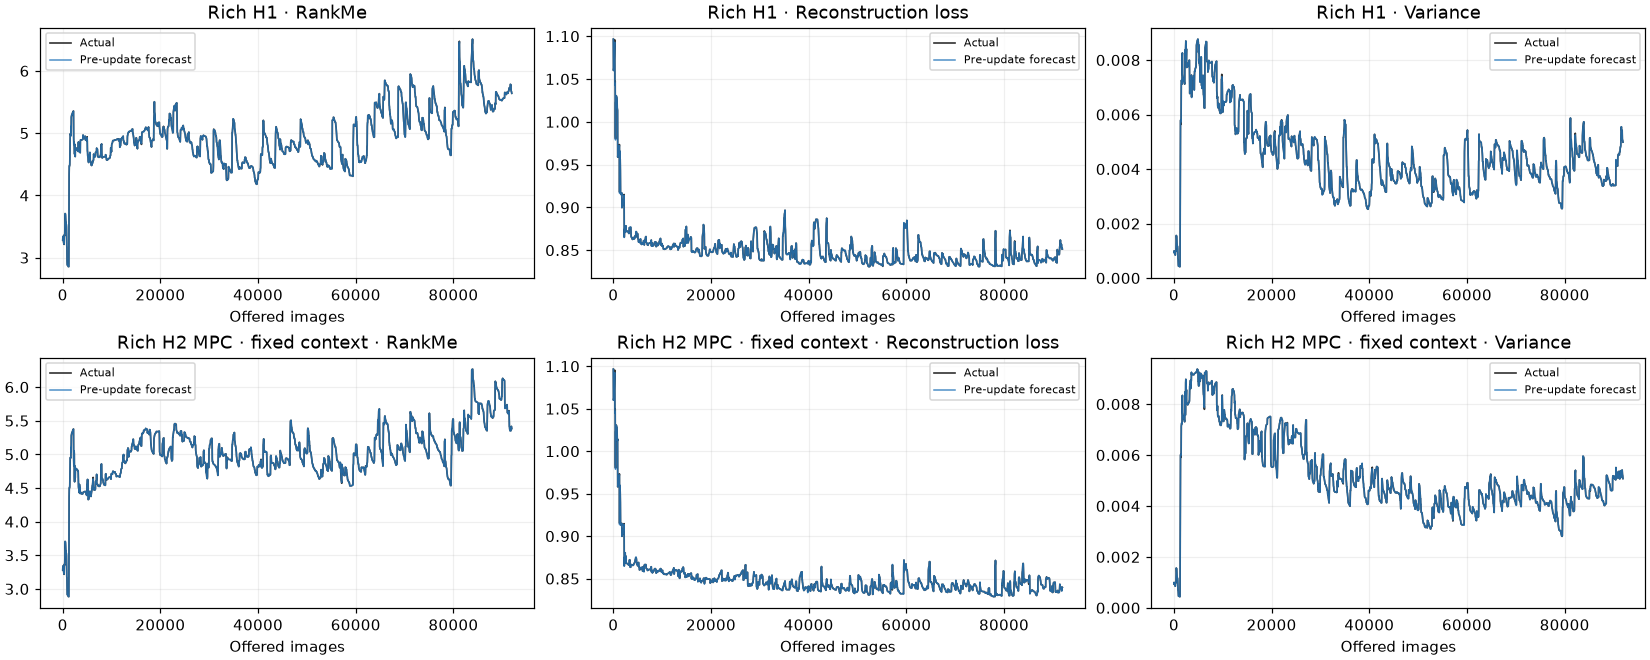

Display subsamples every32 arrivals; RMSE uses all successful positive updates and excludes identity skips.

## One-step positive-update RMSE

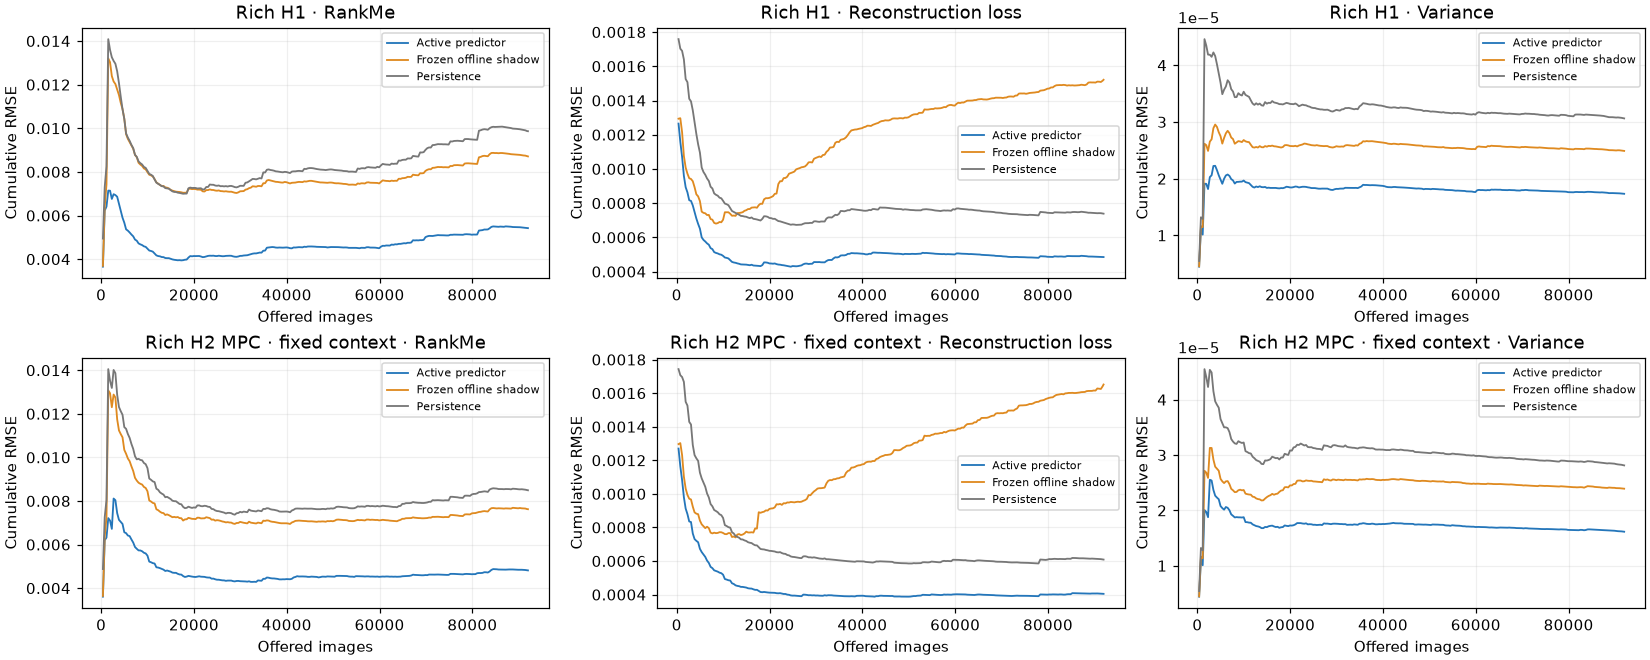



## Two-step nontrivial-window RMSE

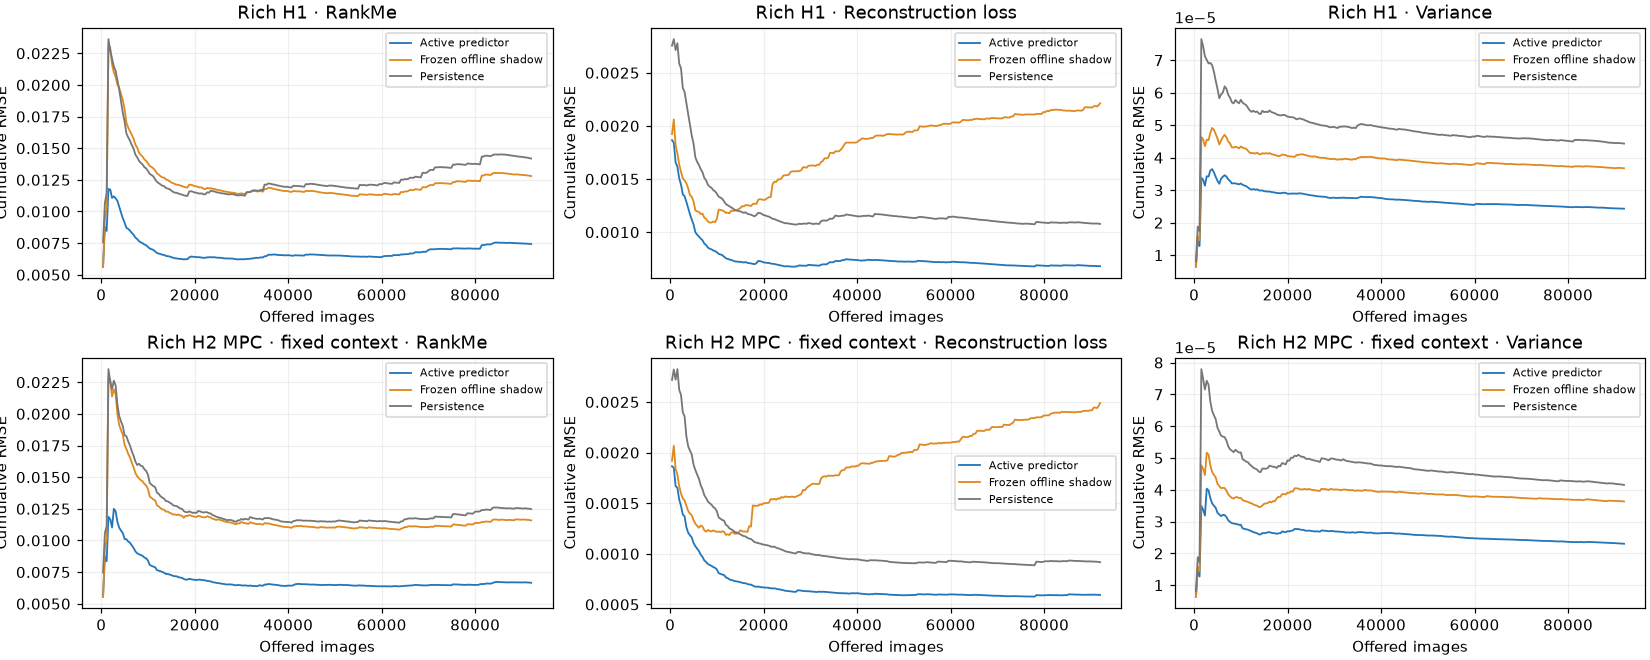



## Plant update and rate budgets

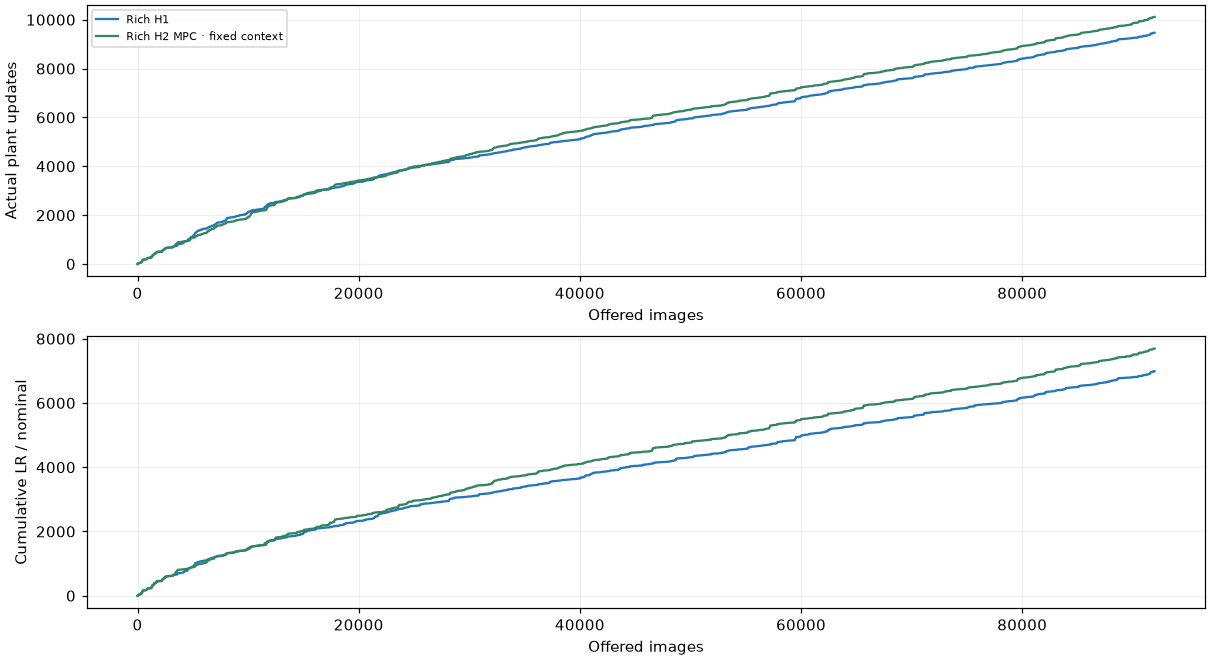



## Transition-model adaptation

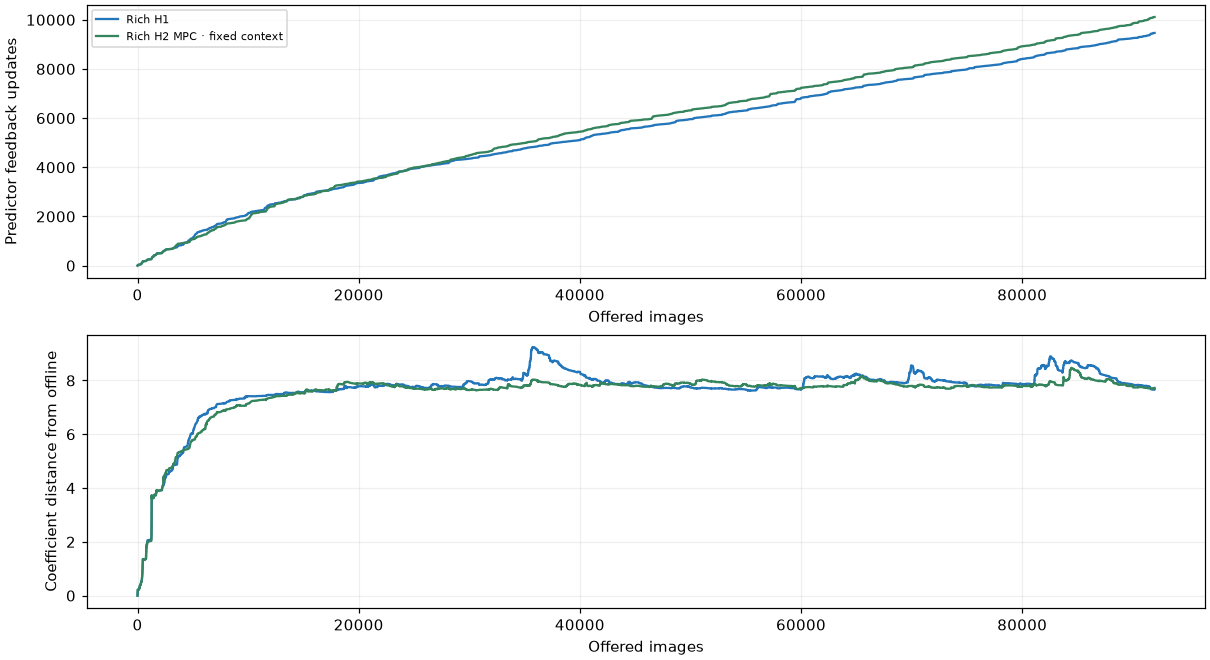



## Executed learning-rate actions

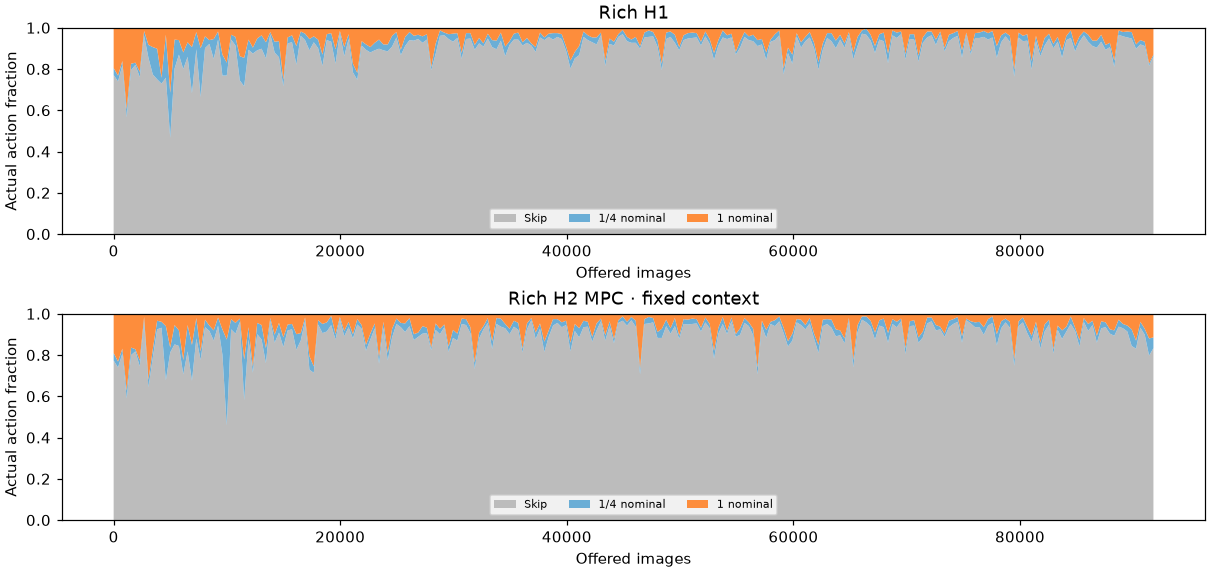



## Actual trained-image losses

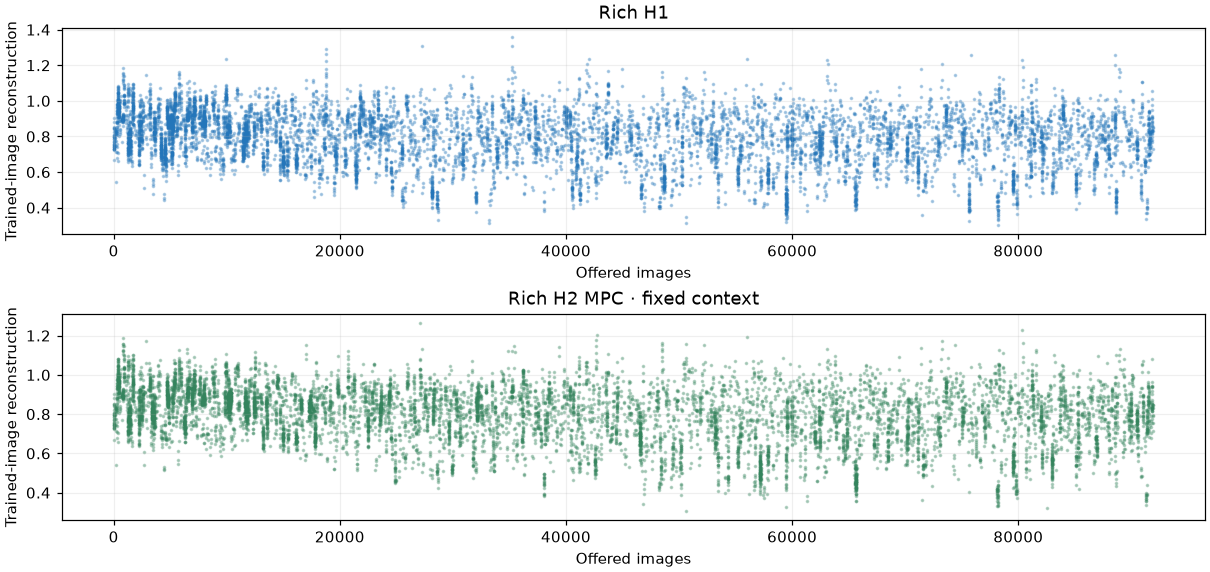



## Audit: linear task metrics

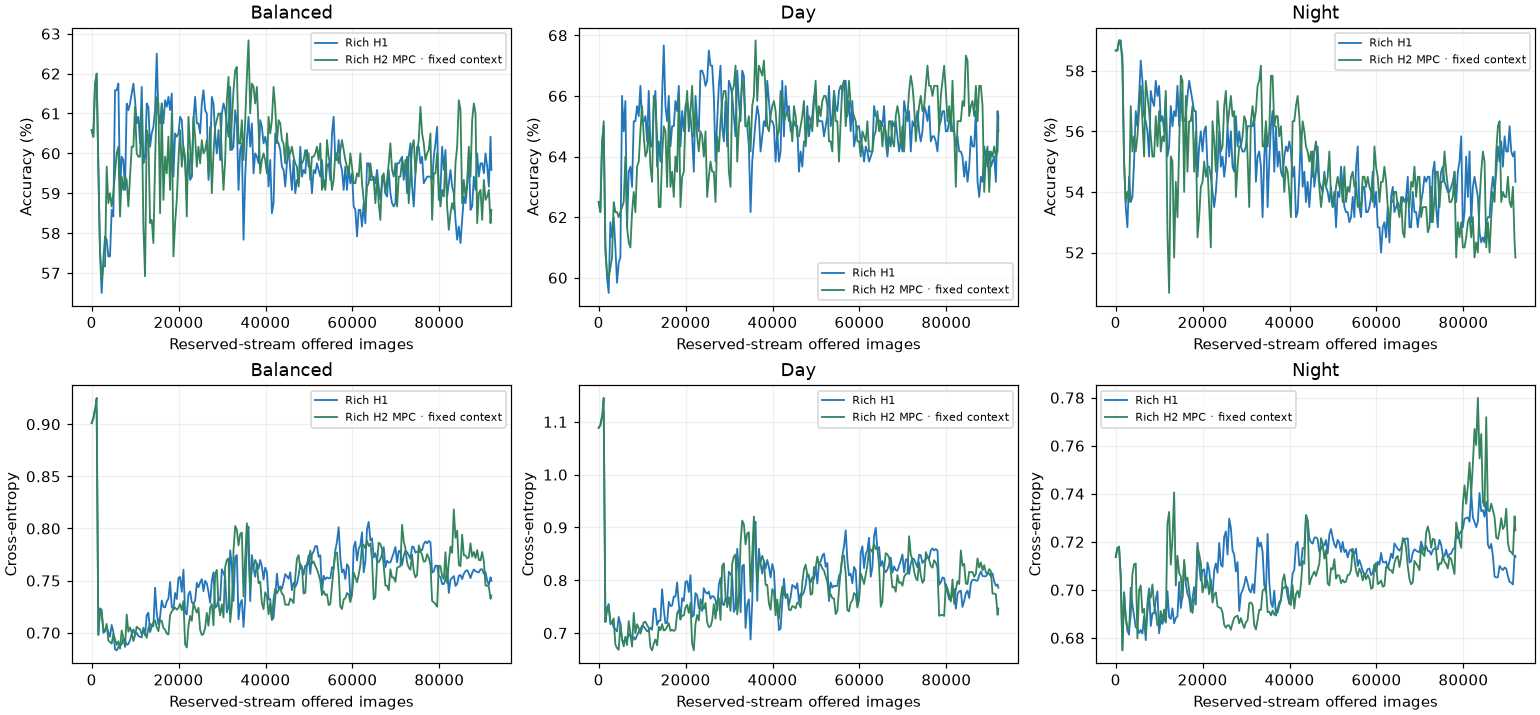



## Audit: knn task metrics

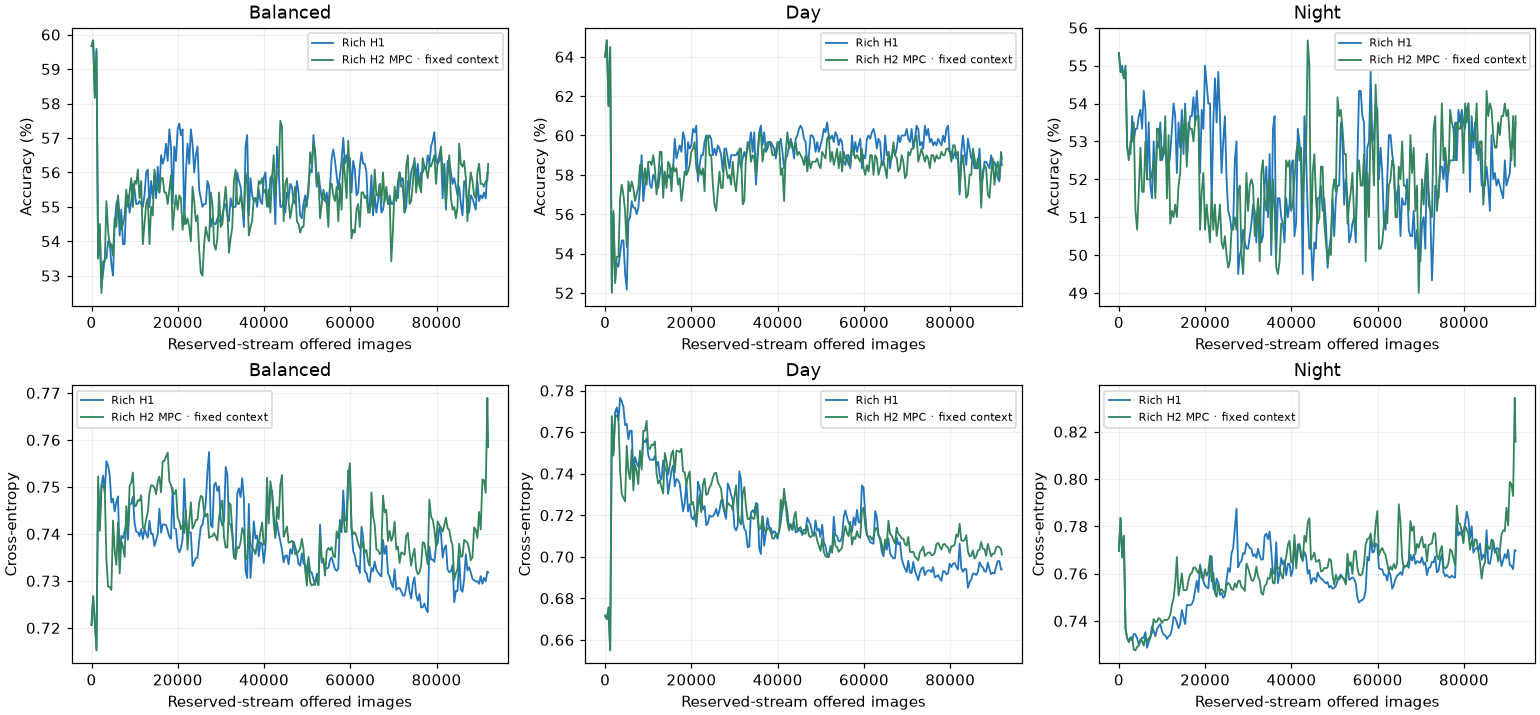



## Previous evaluation: linear task metrics

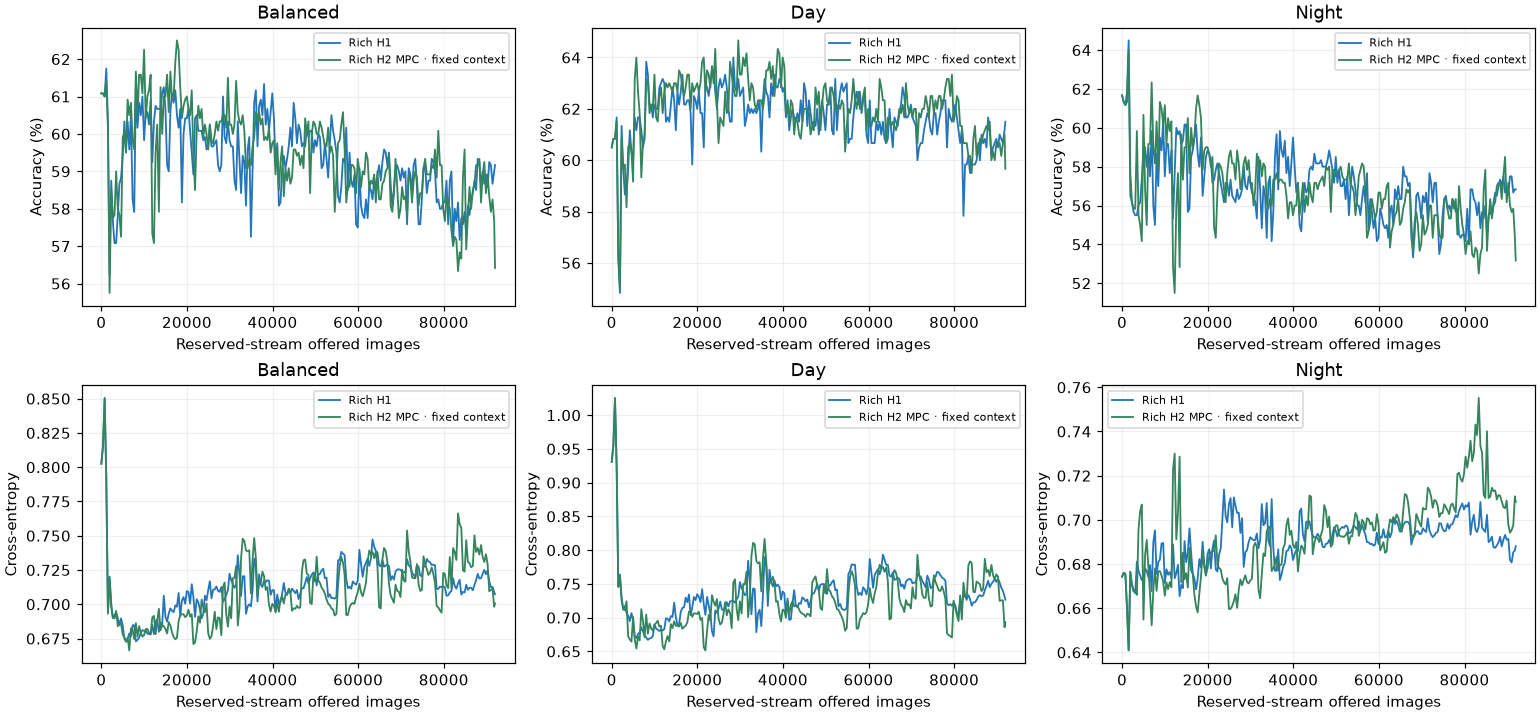



## Previous evaluation: knn task metrics

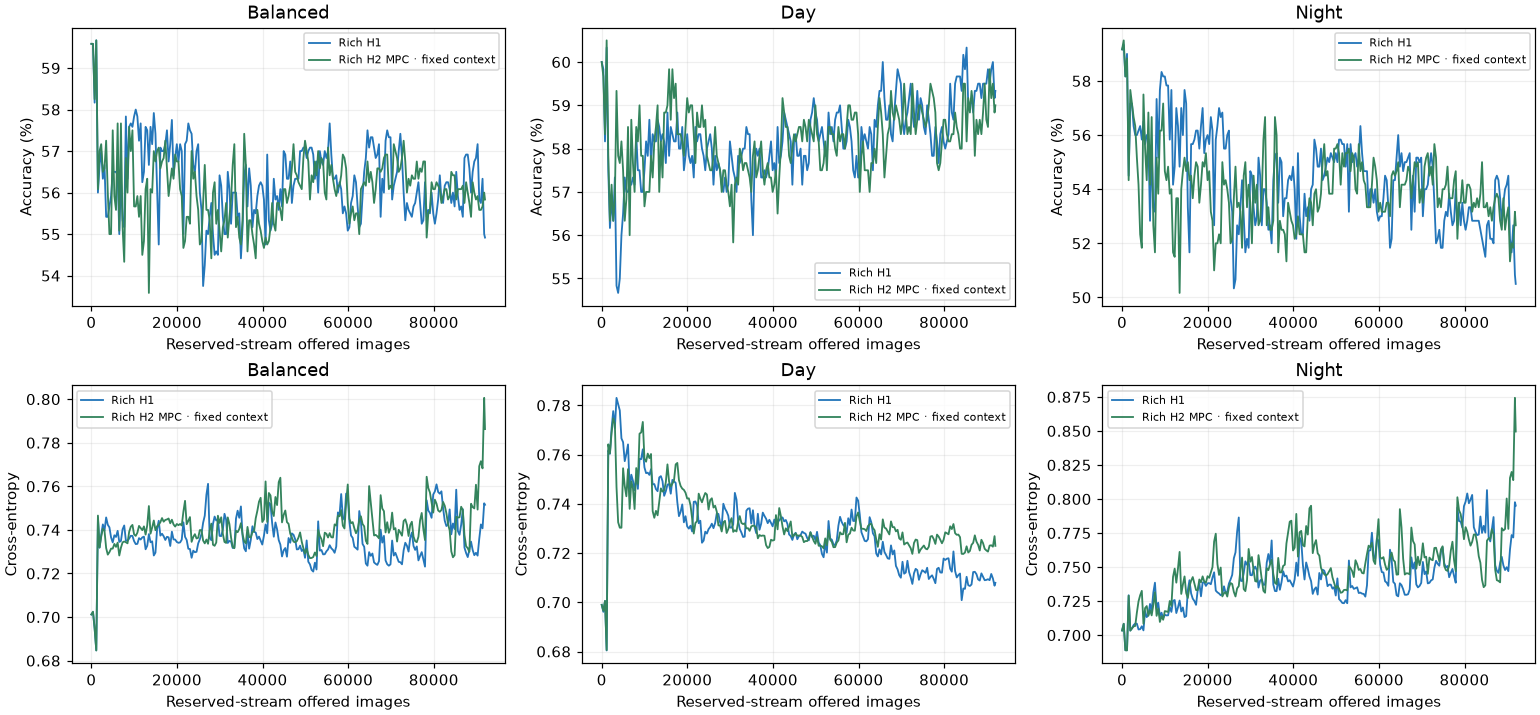



## Additional representation metrics

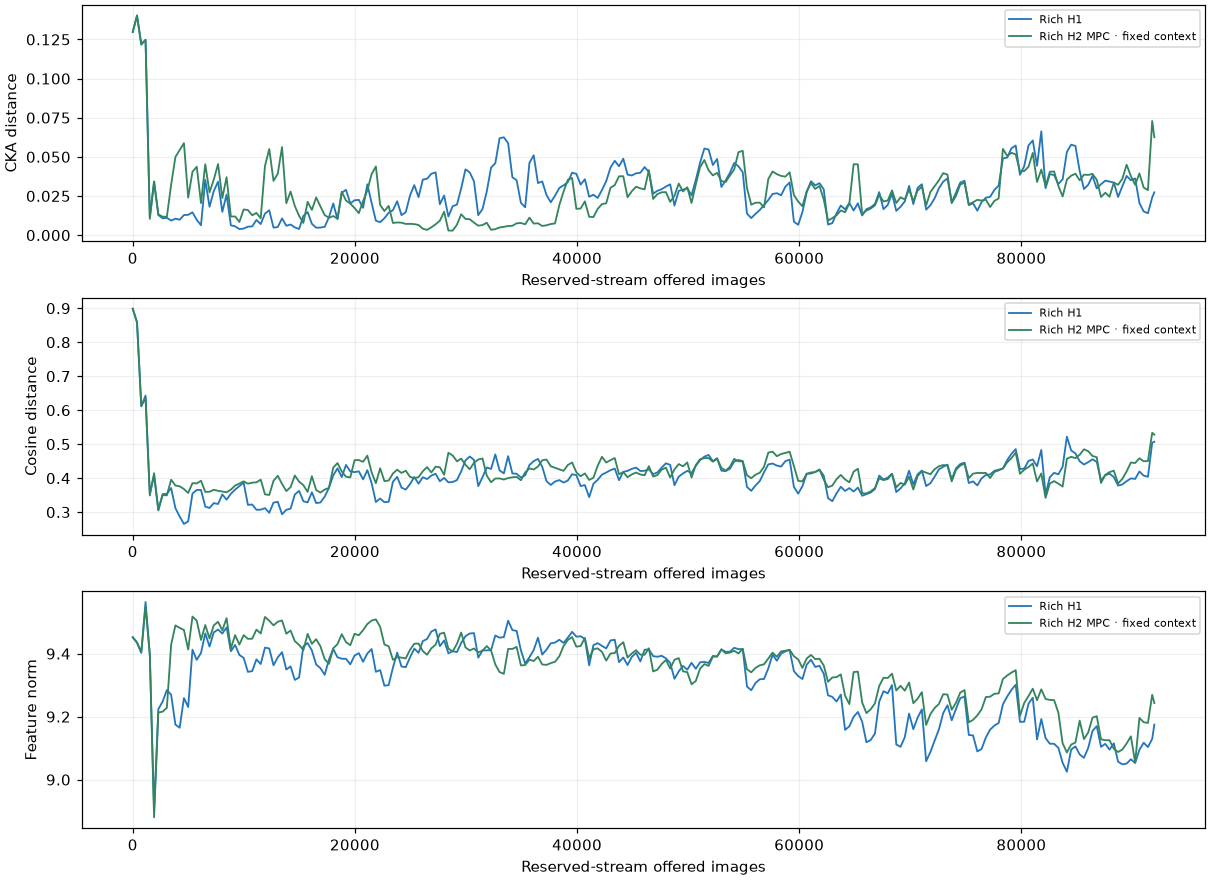



## Secondary evaluation health

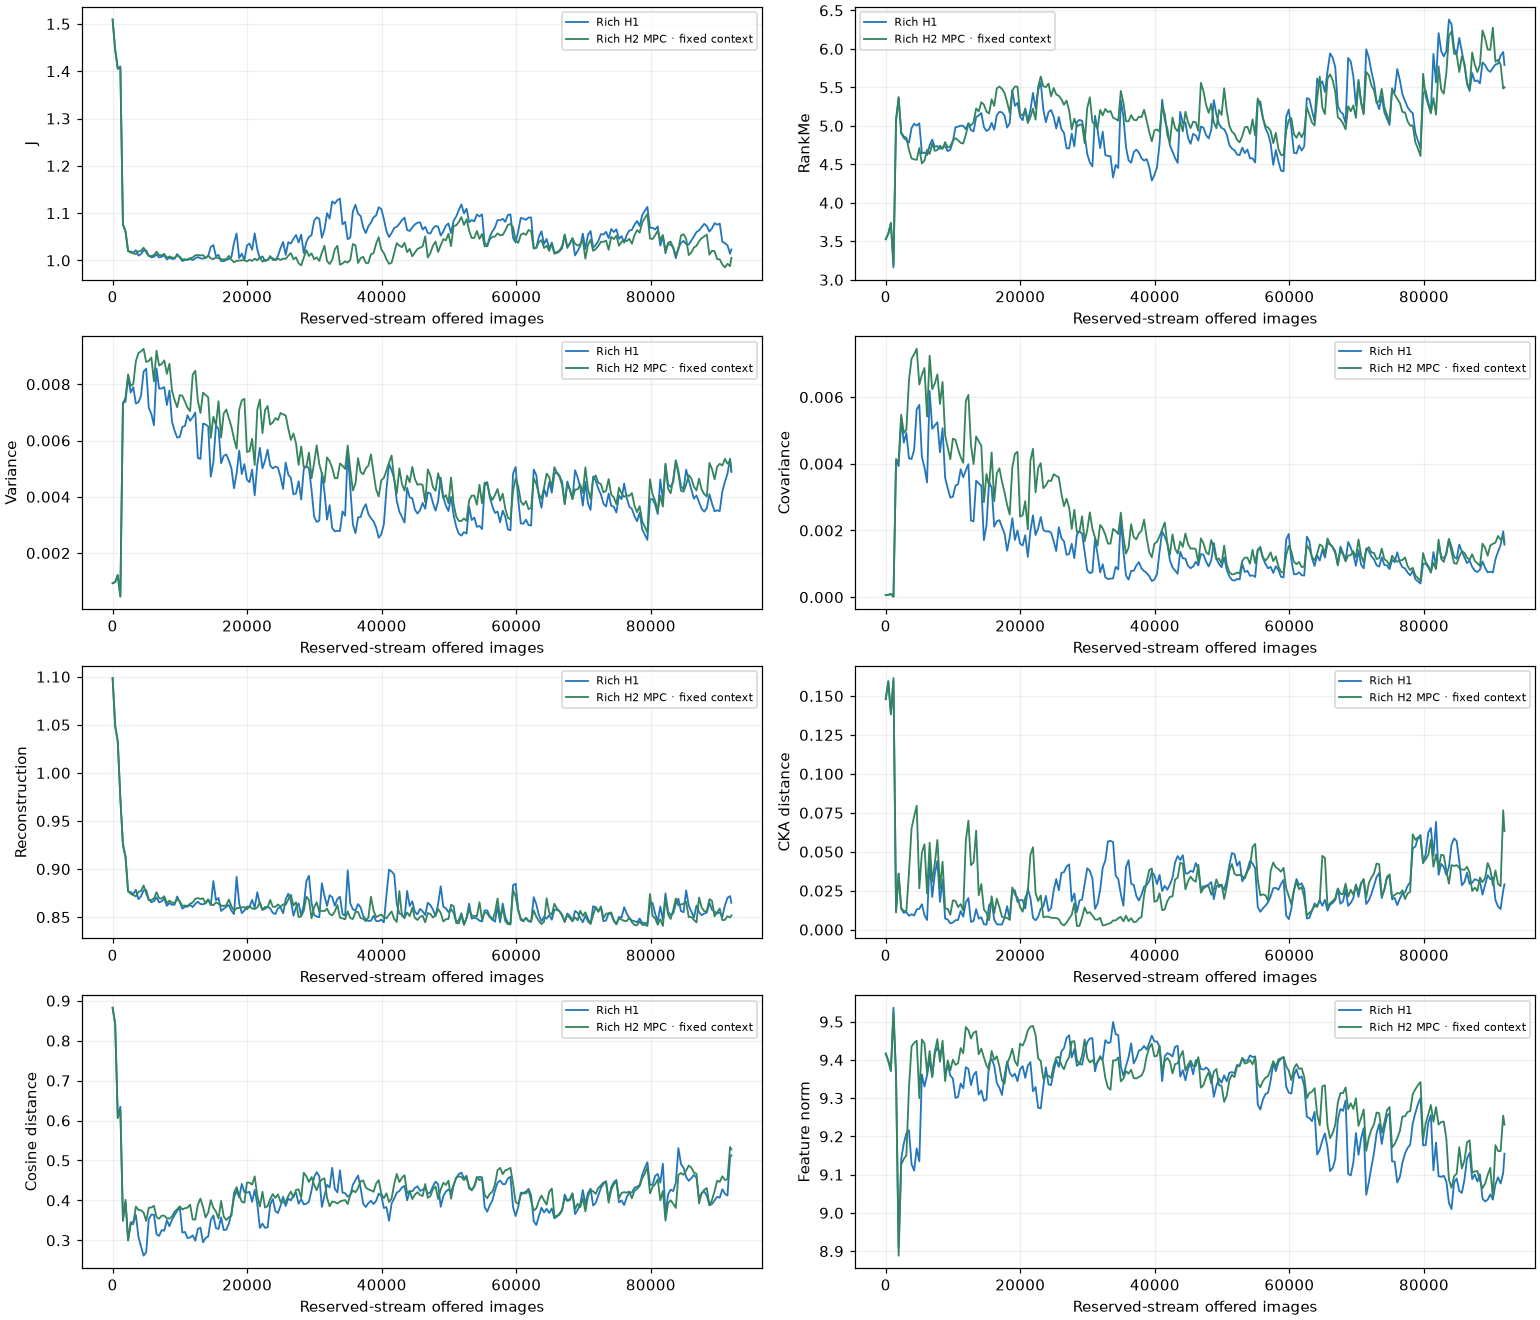

